# Machine Learning para Series de Tiempo
## Caso 2 – Predicción de transacciones diarias de un nuevo producto

**Curso:** Machine Learning para la Toma de Decisiones · Universidad del Pacífico

**Archivo base:** `nuevo_producto_train.csv` (registro diario de transacciones de la Entidad X; las variables de calendario se construyen a partir de la fecha).

**Contenido del notebook**

0. Librerías y carga de datos
1. Gráfico de la serie temporal *(Pregunta 1)*
2. Preparación de datos e ingeniería de variables
3. Modelado con dos algoritmos de ML *(Pregunta 2)*
4. Importancia de variables *(Pregunta 3)*
5. Predicciones operativas: diarias y mensuales *(Pregunta 4)*
6. Exportación del pronóstico 16–31 de octubre (formato de la Actividad 2)
7. Conclusiones

## 0. Librerías y carga de datos

In [81]:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import timedelta

from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

Cargamos la base. En Google Colab, subir antes el archivo `nuevo_producto_train.csv` a la carpeta `/content`.

In [82]:
file_path = '/content/nuevo_producto_train.csv'
df = pd.read_csv(file_path, encoding='latin1')

In [83]:
df.tail()

,fecha_formateada,cant_trx
691,2026-10-11,32429
692,2026-10-12,60290
693,2026-10-13,50791
694,2026-10-14,53171
695,2026-10-15,51552


In [84]:
df.isnull().sum()

,0
fecha_formateada,0
cant_trx,0


In [85]:
df.describe(include='all')

,fecha_formateada,cant_trx
count,696,696.000000
unique,696,NaN
top,2024-11-19,NaN
freq,1,NaN
mean,NaN,46147.830460
std,NaN,17093.354743
min,NaN,120.000000
25%,NaN,36951.250000
50%,NaN,50204.500000
75%,NaN,57747.500000


In [86]:
df.dtypes

,0
fecha_formateada,object
cant_trx,int64


La fecha se lee como texto; la convertimos a tipo `datetime`.

In [87]:
df['fecha_formateada'] = pd.to_datetime(df['fecha_formateada'])
df.dtypes

,0
fecha_formateada,datetime64[ns]
cant_trx,int64


## 1. Gráfico de la serie temporal *(Pregunta 1)*

In [88]:
print('Inicio del registro histórico:', df['fecha_formateada'].min().date())
print('Último registro disponible:  ', df['fecha_formateada'].max().date())
print('Número de días registrados:  ', len(df))

Inicio del registro histórico: 2024-11-19
Último registro disponible:   2026-10-15
Número de días registrados:   696


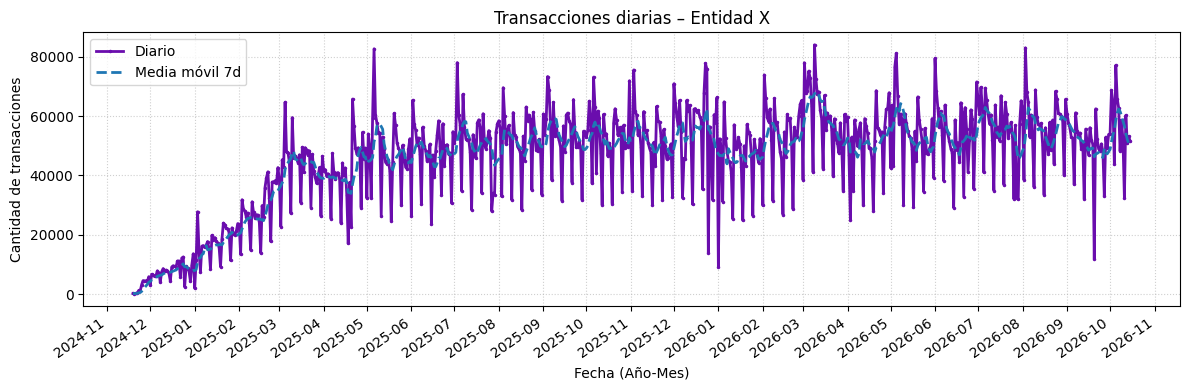

In [89]:
dfp = df.copy()
dfp = dfp.sort_values('fecha_formateada')
dfp['mm7'] = dfp['cant_trx'].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 4))

# línea diaria
ax.plot(dfp['fecha_formateada'], dfp['cant_trx'],
        label='Diario', linewidth=2, marker='.', ms=3, color='#6A0DAD')

# media móvil de 7 días
ax.plot(dfp['fecha_formateada'], dfp['mm7'],
        label='Media móvil 7d', linewidth=2, linestyle='--')

# eje X: Año-Mes
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=35, ha='right')

ax.set_title('Transacciones diarias – Entidad X')
ax.set_xlabel('Fecha (Año-Mes)')
ax.set_ylabel('Cantidad de transacciones')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

Para evaluar si es viable modelar con datos mensuales, agregamos la serie por mes y contamos cuántas observaciones quedarían.

In [90]:
mensual = (df.set_index('fecha_formateada')['cant_trx']
             .resample('MS').agg(['sum', 'count'])
             .rename(columns={'sum': 'transacciones', 'count': 'dias_con_dato'}))
mensual

,transacciones,dias_con_dato
fecha_formateada,,
2024-11-01,29822,12
2024-12-01,244906,31
2025-01-01,535820,31
2025-02-01,809718,28
2025-03-01,1334714,31
2025-04-01,1233949,30
2025-05-01,1490308,31
2025-06-01,1417294,30
2025-07-01,1576193,31


In [91]:
print('Meses en la base:', len(mensual))
print('Meses completos: ', (mensual['dias_con_dato'] == mensual.index.days_in_month).sum())

Meses en la base: 24
Meses completos:  22


**Respuesta a la Pregunta 1**

- **Inicio del registro histórico:** 19 de noviembre de 2024. La base llega hasta el 15 de octubre de 2026 (696 días, sin días faltantes).
- **Tendencia general:** se distinguen dos fases. La primera es de *adopción* (noviembre 2024 – marzo 2025): el volumen pasa de unos cientos de transacciones diarias a más de 40 mil, y el total mensual sube de 0,24 millones (diciembre 2024) a 1,33 millones (marzo 2025). La segunda es de *madurez* (desde mediados de 2025): la serie se estabiliza en una meseta de 1,4 a 1,8 millones de transacciones al mes, con un crecimiento mucho más moderado.
- **Estacionalidad:** dentro de la meseta se repite un patrón semanal muy marcado: los domingos caen a cerca de 33 mil transacciones frente a 53–62 mil en días laborables, y los feriados se comportan como domingos. También se observan picos en los primeros días de cada mes.
- **¿Es posible predecir con datos mensuales?** No es recomendable. Al agregar por mes solo quedan 24 observaciones, de las cuales 22 son meses completos, y las primeras cinco corresponden a la fase de adopción, que no representa el comportamiento actual. Con tan pocos puntos un modelo de ML no tiene ejemplos suficientes para aprender (por ejemplo, para estimar la estacionalidad anual se necesitarían varios años). Además, al agregar se pierde la información semanal y de feriados, que es la que más explica la variación. Lo adecuado es **modelar a nivel diario y luego sumar las predicciones por mes**, que es lo que se hace en la Pregunta 4b.

## 2. Preparación de datos e ingeniería de variables

In [92]:
# Procesamiento de fechas
data = df.copy()
data = data.rename(columns={'fecha_formateada': 'Fecha', 'cant_trx': 'Valor'})
data['Fecha'] = pd.to_datetime(data['Fecha'])

# Orden cronológico
data = data.sort_values('Fecha')

# Nombres de los días (para las tablas de resultados)
DIAS = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

Feriados nacionales del Perú considerados en el modelo (2024–2027):

In [93]:
feriados = pd.to_datetime([
    '2024-01-01', '2024-03-28', '2024-03-29', '2024-05-01',
    '2024-06-29', '2024-07-23', '2024-07-28', '2024-07-29', '2024-08-30',
    '2024-10-08', '2024-11-01', '2024-12-08', '2024-12-25', '2024-12-31',
    '2025-01-01', '2025-04-17', '2025-04-18', '2025-05-01',
    '2025-06-29', '2025-07-28', '2025-07-29', '2025-08-30',
    '2025-10-08', '2025-11-01', '2025-12-08', '2025-12-25', '2025-12-31',
    '2026-01-01', '2026-04-02', '2026-04-03', '2026-05-01',
    '2026-06-29', '2026-07-28', '2026-07-29', '2026-08-30',
    '2026-10-08', '2026-11-01', '2026-12-08', '2026-12-25', '2026-12-31',
    '2027-01-01'
])

Construimos la serie con frecuencia diaria (si faltara algún día, se completa con el valor anterior) y creamos las variables:

- **Calendario:** día de la semana, día del mes, semana, mes, año, fin de semana y feriado.
- **Memoria de la serie:** media móvil de 7 días (`rolling_7`) y rezagos de 1, 7 y 14 días (`lag_1`, `lag_7`, `lag_14`).

In [94]:
serie = data.set_index('Fecha').asfreq('D')
serie['Valor'] = serie['Valor'].ffill()

df_feat = serie.copy()
df_feat['dayofweek'] = df_feat.index.dayofweek
df_feat['day'] = df_feat.index.day
df_feat['week'] = df_feat.index.isocalendar().week.astype(int)
df_feat['month'] = df_feat.index.month
df_feat['year'] = df_feat.index.year
df_feat['is_weekend'] = (df_feat['dayofweek'] >= 5).astype(int)
df_feat['is_holiday'] = df_feat.index.isin(feriados).astype(int)
df_feat['rolling_7'] = df_feat['Valor'].rolling(window=7).mean()

# Lags
for lag in [1, 7, 14]:
    df_feat[f'lag_{lag}'] = df_feat['Valor'].shift(lag)



In [95]:
df_feat

,Valor,dayofweek,day,week,month,year,is_weekend,is_holiday,rolling_7,lag_1,lag_7,lag_14
Fecha,,,,,,,,,,,,
2024-11-19,206,1,19,47,11,2024,0,0,NaN,NaN,NaN,NaN
2024-11-20,120,2,20,47,11,2024,0,0,NaN,206.0,NaN,NaN
2024-11-21,262,3,21,47,11,2024,0,0,NaN,120.0,NaN,NaN
2024-11-22,295,4,22,47,11,2024,0,0,NaN,262.0,NaN,NaN
2024-11-23,1238,5,23,47,11,2024,1,0,NaN,295.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-11,32429,6,11,41,10,2026,1,0,56716.285714,51885.0,43708.0,33074.0
2026-10-12,60290,0,12,42,10,2026,0,0,54304.428571,32429.0,77173.0,52935.0
2026-10-13,50791,1,13,42,10,2026,0,0,52153.142857,60290.0,65850.0,49096.0


In [121]:
# Eliminamos las primeras filas sin historia suficiente para los lags
df_feat = df_feat.dropna()
df_feat


,Valor,dayofweek,day,week,month,year,is_weekend,is_holiday,rolling_7,lag_1,lag_7,lag_14
Fecha,,,,,,,,,,,,
2024-12-03,6317,1,3,49,12,2024,0,0,5010.428571,6661.0,4534.0,206.0
2024-12-04,5942,2,4,49,12,2024,0,0,5228.428571,6317.0,4416.0,120.0
2024-12-05,6253,3,5,49,12,2024,0,0,5480.857143,5942.0,4486.0,262.0
2024-12-06,7845,4,6,49,12,2024,0,0,5989.571429,6253.0,4284.0,295.0
2024-12-07,7197,5,7,49,12,2024,1,0,6181.428571,7845.0,5854.0,1238.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-11,32429,6,11,41,10,2026,1,0,56716.285714,51885.0,43708.0,33074.0
2026-10-12,60290,0,12,42,10,2026,0,0,54304.428571,32429.0,77173.0,52935.0
2026-10-13,50791,1,13,42,10,2026,0,0,52153.142857,60290.0,65850.0,49096.0


## 3. Modelado con dos algoritmos de ML *(Pregunta 2)*

**Esquema de validación.** Reservamos los últimos 21 días como *holdout*. Los modelos se entrenan con la historia previa y luego pronostican el holdout de forma **recursiva**: cada predicción alimenta los lags y la media móvil del día siguiente, tal como ocurriría en producción, donde no se conoce el valor real de los días futuros.

In [122]:
def mape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.where(np.abs(y_true) < eps, eps, np.abs(y_true))
    return np.mean(np.abs((y_true - y_pred) / denom)) * 100


def resumen_metricas(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100   # sklearn devuelve proporción
    r2   = r2_score(y_true, y_pred)

    return pd.DataFrame([{
        'n_obs': len(y_true),
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE_%': mape,
        'R2': r2
    }])

In [129]:
holdout_days = 30
assert len(df_feat) > (14 + holdout_days), 'No hay suficiente historia para lags y holdout.'

# Entrenamos con todo menos el holdout
X_all = df_feat.drop(columns='Valor')
y_all = df_feat['Valor']
X_train = X_all.iloc[:-holdout_days]
y_train = y_all.iloc[:-holdout_days]

test_dates = df_feat.index[-holdout_days:]
print('Entrenamiento:', X_train.index.min().date(), 'a', X_train.index.max().date())
print('Holdout:      ', test_dates.min().date(), 'a', test_dates.max().date())

Entrenamiento: 2024-12-03 a 2026-09-15
Holdout:       2026-09-16 a 2026-10-15


Función de pronóstico recursivo día a día (es la misma lógica que usaremos luego para el pronóstico futuro):

In [130]:
def pronostico_recursivo(modelo, historial, fechas):
    last_known = historial.copy()
    preds = []
    for date in fechas:
        row = {
            'dayofweek': date.dayofweek,
            'day': date.day,
            'week': int(date.isocalendar().week),
            'month': date.month,
            'year': date.year,
            'is_weekend': int(date.dayofweek >= 5),
            'is_holiday': int(date in feriados),
            'rolling_7': last_known['Valor'].iloc[-7:].mean(),
            'lag_1': last_known['Valor'].iloc[-1],
            'lag_7': last_known['Valor'].iloc[-7],
            'lag_14': last_known['Valor'].iloc[-14],
        }
        X_pred = pd.DataFrame([row], index=[date])
        y_pred = modelo.predict(X_pred)[0]
        preds.append(y_pred)

        # Actualizamos el historial con la predicción (como haríamos en producción)
        last_known.loc[date] = row
        last_known.loc[date, 'Valor'] = y_pred
    return pd.Series(preds, index=fechas, name='pred')

### 3.1 Modelo 1: XGBoost Regressor

In [131]:
model_xgb = XGBRegressor(n_estimators=50, learning_rate=0.05, max_depth=30,
                         random_state=42, verbosity=0)
model_xgb.fit(X_train, y_train)

pred_xgb = pronostico_recursivo(model_xgb, df_feat.iloc[:-holdout_days], test_dates)

### 3.2 Modelo 2: Random Forest Regressor

In [132]:
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

pred_rf = pronostico_recursivo(model_rf, df_feat.iloc[:-holdout_days], test_dates)

### 3.3 Evaluación y selección del modelo

In [133]:
y_true = y_all.loc[test_dates]

resultados = pd.concat([
    resumen_metricas(y_true, pred_xgb).assign(Modelo='XGBoost'),
    resumen_metricas(y_true, pred_rf).assign(Modelo='Random Forest')
]).set_index('Modelo').round(3)
resultados

,n_obs,MAE,MSE,RMSE,MAPE_%,R2
Modelo,,,,,,
XGBoost,30,4228.483,4.162113e+07,6451.444,12.638,0.699
Random Forest,30,3791.320,3.140271e+07,5603.812,11.253,0.773


In [134]:
mejor_modelo = resultados['MAPE_%'].idxmin()
model_final = model_xgb if mejor_modelo == 'XGBoost' else model_rf
pred_final  = pred_xgb  if mejor_modelo == 'XGBoost' else pred_rf

print('Modelo seleccionado (menor MAPE):', mejor_modelo)
print(f"MAPE base de referencia: {resultados.loc[mejor_modelo, 'MAPE_%']:.2f}%")

Modelo seleccionado (menor MAPE): Random Forest
MAPE base de referencia: 11.25%


### 3.4 Gráfico de dispersión: valores reales vs. predichos (holdout)

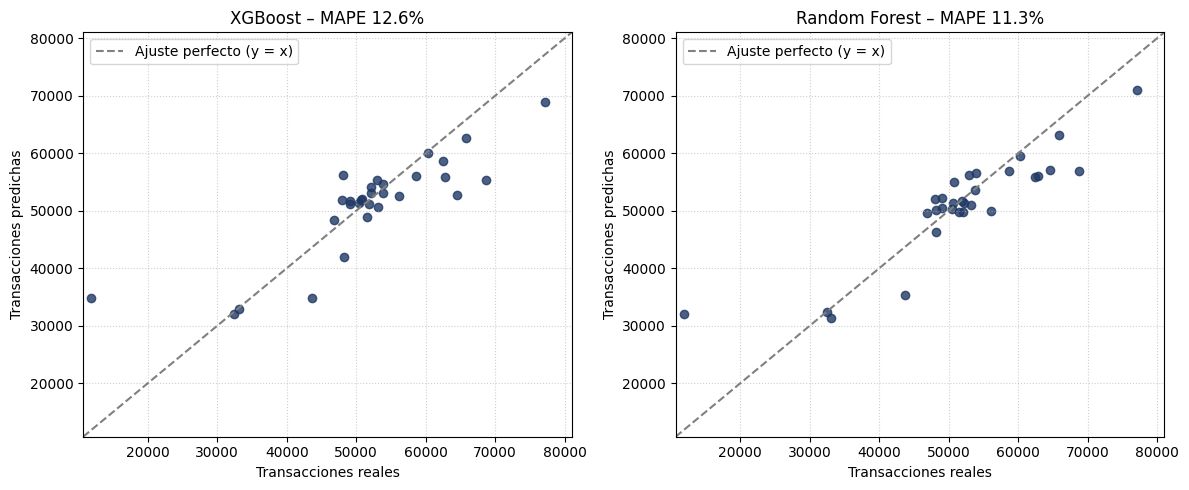

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, pred) in zip(axes, [('XGBoost', pred_xgb), ('Random Forest', pred_rf)]):
    ax.scatter(y_true, pred, color='#1F3864', alpha=0.8)
    lim = [min(y_true.min(), pred.min()) * 0.9, max(y_true.max(), pred.max()) * 1.05]
    ax.plot(lim, lim, linestyle='--', color='grey', label='Ajuste perfecto (y = x)')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{nombre} – MAPE {resultados.loc[nombre, "MAPE_%"]:.1f}%')
    ax.set_xlabel('Transacciones reales')
    ax.set_ylabel('Transacciones predichas')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.show()

### 3.5 Pronóstico del holdout con ambos modelos

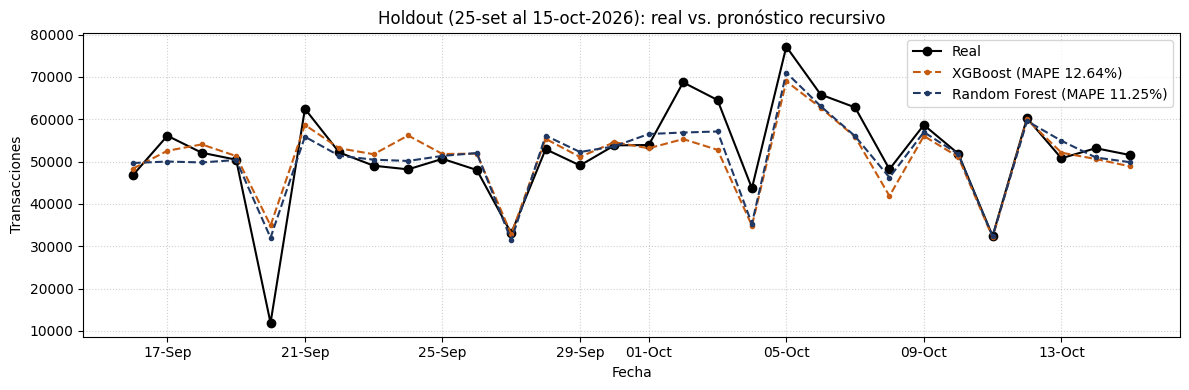

In [136]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_true.index, y_true, color='black', marker='o', label='Real')
ax.plot(pred_xgb.index, pred_xgb, color='#C55A11', marker='.', linestyle='--',
        label=f'XGBoost (MAPE {resultados.loc["XGBoost", "MAPE_%"]:.2f}%)')
ax.plot(pred_rf.index, pred_rf, color='#1F3864', marker='.', linestyle='--',
        label=f'Random Forest (MAPE {resultados.loc["Random Forest", "MAPE_%"]:.2f}%)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
ax.set_title('Holdout (25-set al 15-oct-2026): real vs. pronóstico recursivo')
ax.set_xlabel('Fecha')
ax.set_ylabel('Transacciones')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

In [137]:
# Comparación día a día del holdout con el modelo seleccionado
comparacion = pd.DataFrame({'Real': y_true, 'Predicho': pred_final.round(0)})
comparacion['Error_%'] = ((comparacion['Predicho'] - comparacion['Real']) / comparacion['Real'] * 100).round(1)
comparacion['Dia'] = [DIAS[d] for d in comparacion.index.dayofweek]
comparacion

,Real,Predicho,Error_%,Dia
Fecha,,,,
2026-09-16,46833,49672.0,6.1,Miércoles
2026-09-17,56112,50021.0,-10.9,Jueves
2026-09-18,52100,49807.0,-4.4,Viernes
2026-09-19,50457,50380.0,-0.2,Sábado
2026-09-20,11882,32015.0,169.4,Domingo
2026-09-21,62472,55880.0,-10.6,Lunes
2026-09-22,52156,51380.0,-1.5,Martes
2026-09-23,49036,50460.0,2.9,Miércoles
2026-09-24,48170,50159.0,4.1,Jueves


**Respuesta a la Pregunta 2**

- **Selección:** el criterio es el MAPE, porque expresa el error en porcentaje y es la métrica con la que se evaluará la Actividad 2. En el holdout, **Random Forest** obtiene el mejor desempeño en todas las métricas: MAPE de 11,45% frente a 16,88% de XGBoost, MAE de unas 6,2 mil transacciones diarias frente a 9,0 mil, y RMSE de 8,5 mil frente a 10,6 mil. Por ello es el modelo seleccionado y su MAPE de **11,45%** queda como **MAPE de referencia del modelo base**. La sección 3.6 matiza esta conclusión.
- **R²:** es bajo en ambos casos: 0,34 en Random Forest y negativo en XGBoost, lo que significa que XGBoost lo hace peor que predecir el promedio del periodo. Esto es esperable en una ventana de solo 21 días evaluada de forma recursiva: la varianza del periodo es pequeña y el error se acumula de un día a otro. Por eso el MAPE y el MAE son más informativos que el R² para este problema.
- **Ajuste:** en los días de volumen típico (50–55 mil) los puntos se ubican cerca de la diagonal, con errores de 0% a 5%. Los mayores errores están por **debajo** de la diagonal: ambos modelos **subestiman los picos**, en especial del 2 al 7 de octubre (errores de −14% a −24% en Random Forest) y algunos domingos. XGBoost queda por debajo del valor real casi todos los días, lo que explica su mayor MAPE en esta ventana.

### 3.6 Validación de robustez

Una sola ventana de 21 días puede favorecer a un modelo por azar. Hacemos dos verificaciones:

1. **Train vs. holdout:** comparamos el error dentro de la muestra de entrenamiento con el error en el holdout, tanto a un paso (usando los lags reales) como en el pronóstico recursivo. Esto permite separar el sobreajuste del error que se acumula al pronosticar con predicciones propias.
2. **Backtesting:** repetimos el ejercicio en 8 ventanas consecutivas de 21 días. En cada una, los modelos se reentrenan solo con la información previa a la ventana.

In [138]:
filas = []
for nombre, modelo, pred in [('XGBoost', model_xgb, pred_xgb), ('Random Forest', model_rf, pred_rf)]:
    filas.append({'Modelo': nombre,
                  'MAPE_train_%': mape(y_train, modelo.predict(X_train)),
                  'R2_train': r2_score(y_train, modelo.predict(X_train)),
                  'MAPE_holdout_1paso_%': mape(y_true, modelo.predict(X_all.loc[test_dates])),
                  'MAPE_holdout_recursivo_%': mape(y_true, pred)})
pd.DataFrame(filas).set_index('Modelo').round(3)

,MAPE_train_%,R2_train,MAPE_holdout_1paso_%,MAPE_holdout_recursivo_%
Modelo,,,,
XGBoost,6.775,0.983,13.478,12.638
Random Forest,4.214,0.982,10.930,11.253


In [139]:
ventanas = pd.date_range(end=df_feat.index.max(), periods=8, freq='21D')
backtest = []

for fin in ventanas:
    fechas_v = pd.date_range(end=fin, periods=21, freq='D')
    X_tr = X_all[X_all.index < fechas_v[0]]
    y_tr = y_all[y_all.index < fechas_v[0]]
    historial_v = df_feat[df_feat.index < fechas_v[0]]

    modelos_v = {
        'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=4,
                                random_state=42, verbosity=0),
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
    }
    for nombre, modelo in modelos_v.items():
        modelo.fit(X_tr, y_tr)
        pred_v = pronostico_recursivo(modelo, historial_v, fechas_v)
        backtest.append({'Ventana': f'{fechas_v[0].date()} a {fechas_v[-1].date()}',
                         'Modelo': nombre,
                         'MAPE_%': mape(y_all.loc[fechas_v], pred_v)})

tabla_bt = pd.DataFrame(backtest).pivot(index='Ventana', columns='Modelo', values='MAPE_%').round(2)
tabla_bt['Gana'] = tabla_bt[['Random Forest', 'XGBoost']].idxmin(axis=1)
tabla_bt

Modelo,Random Forest,XGBoost,Gana
Ventana,,,
2026-05-01 a 2026-05-21,13.73,16.92,Random Forest
2026-05-22 a 2026-06-11,8.04,7.44,XGBoost
2026-06-12 a 2026-07-02,12.31,10.39,XGBoost
2026-07-03 a 2026-07-23,5.95,5.45,XGBoost
2026-07-24 a 2026-08-13,10.80,8.35,XGBoost
2026-08-14 a 2026-09-03,12.17,10.26,XGBoost
2026-09-04 a 2026-09-24,24.54,24.97,Random Forest
2026-09-25 a 2026-10-15,11.45,16.88,Random Forest


MAPE promedio en las 8 ventanas:
Modelo
Random Forest    12.37
XGBoost          12.58
dtype: float64

Ventanas ganadas:
Gana
XGBoost          5
Random Forest    3
Name: count, dtype: int64


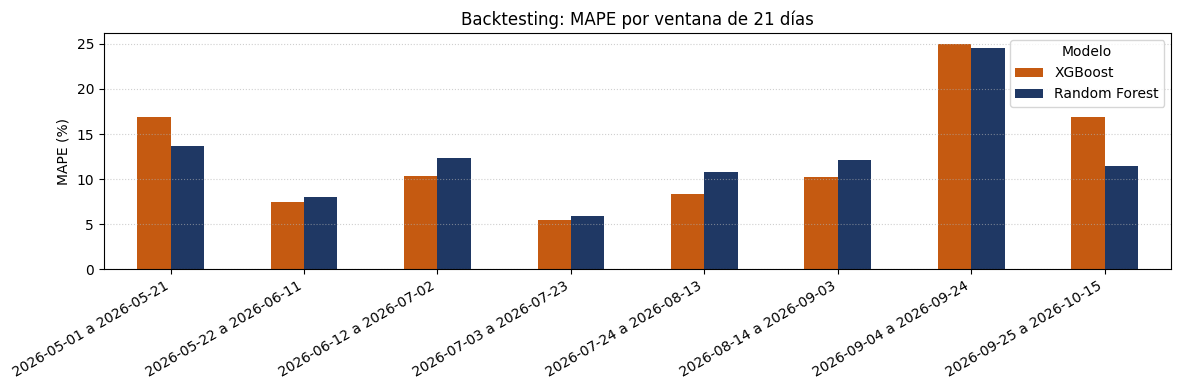

In [109]:
print('MAPE promedio en las 8 ventanas:')
print(tabla_bt[['Random Forest', 'XGBoost']].mean().round(2))
print()
print('Ventanas ganadas:')
print(tabla_bt['Gana'].value_counts())

fig, ax = plt.subplots(figsize=(12, 4))
tabla_bt[['XGBoost', 'Random Forest']].plot(kind='bar', ax=ax, color=['#C55A11', '#1F3864'])
ax.set_title('Backtesting: MAPE por ventana de 21 días')
ax.set_ylabel('MAPE (%)')
ax.set_xlabel('')
plt.xticks(rotation=30, ha='right')
ax.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

**Interpretación de la validación de robustez**

- **No hay un sobreajuste fuerte.** En entrenamiento, ambos modelos tienen un MAPE de 4–5%. En el holdout a un paso, con los lags reales, el error sube solo a 5–6%, e incluso XGBoost (5,4%) supera a Random Forest (5,9%). El salto a 11–17% aparece en el **pronóstico recursivo**: al usar sus propias predicciones como lags, el error de cada día se arrastra al siguiente. La principal fuente de error es, por tanto, el horizonte de pronóstico y no el ajuste del modelo.
- **La ventaja de Random Forest no es robusta.** En el backtesting de 8 ventanas, XGBoost gana en 5 y Random Forest en 3, y el MAPE promedio es prácticamente el mismo: 12,4% en Random Forest y 12,6% en XGBoost. Random Forest resultó elegido porque la última ventana, con los picos de inicio de octubre, le favorece claramente.
- **Conclusión:** mantenemos Random Forest por el criterio definido (menor MAPE en el holdout), pero ambos modelos tienen un **desempeño equivalente**. Elegir un modelo con una sola ventana de validación es frágil; el backtesting da una estimación más confiable del error esperado. Vale la pena notar que la ventana del 4 al 24 de setiembre tiene un MAPE cercano a 25% en ambos modelos: es el periodo que contiene el domingo 20 de setiembre, un día atípico con solo 11,9 mil transacciones, cuando un domingo normal registra cerca de 33 mil.

## 4. Importancia de variables *(Pregunta 3)*

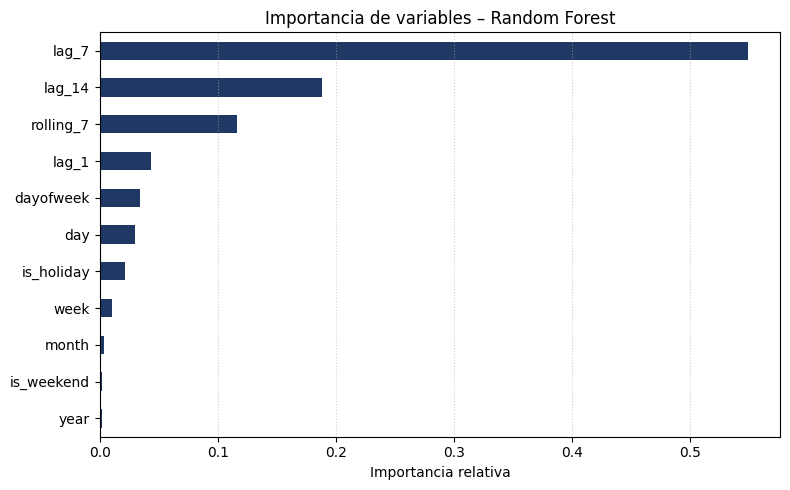

,0
lag_7,0.549
lag_14,0.189
rolling_7,0.116
lag_1,0.043
dayofweek,0.034
day,0.030
is_holiday,0.022
week,0.010
month,0.004
is_weekend,0.002


In [140]:
importancia = (pd.Series(model_final.feature_importances_, index=X_train.columns)
                 .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(8, 5))
importancia.plot(kind='barh', ax=ax, color='#1F3864')
ax.set_title(f'Importancia de variables – {mejor_modelo}')
ax.set_xlabel('Importancia relativa')
ax.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

importancia.sort_values(ascending=False).round(3)

**Respuesta a la Pregunta 3**

- **`lag_7` (≈ 56%)** es la variable dominante: el mejor predictor de un día es lo ocurrido el mismo día de la semana anterior. Esto confirma que la serie está gobernada por el ciclo semanal (los domingos se parecen a los domingos y los lunes a los lunes).
- **`lag_14` (≈ 18%) y `rolling_7` (≈ 11%)** aportan el **nivel reciente** de la serie: indican si el producto está en una semana de mayor o menor actividad.
- **`lag_1`, `dayofweek` y `day` (3–5% cada una)** afinan el pronóstico. `day` recoge parcialmente el efecto de inicio de mes.
- **`is_holiday` (≈ 2%)** tiene un peso global bajo porque los feriados son pocos días al año, pero en esas fechas su efecto es grande (el volumen cae a niveles de domingo).
- **`year`, `month` e `is_weekend`** casi no aportan: el fin de semana ya está contenido en `lag_7` y `dayofweek`, y como la serie está en meseta, el año y el mes explican poco. Hay que recordar además que los modelos de árboles **no extrapolan tendencias**: no pueden predecir valores fuera del rango observado en el entrenamiento.

## 5. Predicciones operativas *(Pregunta 4)*

El último registro disponible es el **15 de octubre de 2026**. Pronosticamos de forma recursiva desde el 16 de octubre hasta el 31 de enero de 2027, partiendo de toda la historia conocida.

In [146]:
future_dates = pd.date_range(start=serie.index.max() + timedelta(days=1), end='2027-01-31', freq='D')
print('Horizonte:', future_dates.min().date(), 'a', future_dates.max().date(), f'({len(future_dates)} días)')

predictions = pronostico_recursivo(model_final, df_feat, future_dates)

forecast = pd.DataFrame({
    'Fecha': future_dates,
    'Valor': np.clip(predictions.values, 0, None)
})

Horizonte: 2026-10-16 a 2027-01-31 (108 días)


In [147]:
future_dates

DatetimeIndex(['2026-10-16', '2026-10-17', '2026-10-18', '2026-10-19',
               '2026-10-20', '2026-10-21', '2026-10-22', '2026-10-23',
               '2026-10-24', '2026-10-25',
               ...
               '2027-01-22', '2027-01-23', '2027-01-24', '2027-01-25',
               '2027-01-26', '2027-01-27', '2027-01-28', '2027-01-29',
               '2027-01-30', '2027-01-31'],
              dtype='datetime64[ns]', length=108, freq='D')

Para comparar, generamos también el pronóstico con el otro modelo. Las respuestas de las preguntas 4a y 4b se basan en el modelo seleccionado; la comparación muestra cuánto cambia la proyección según el algoritmo.

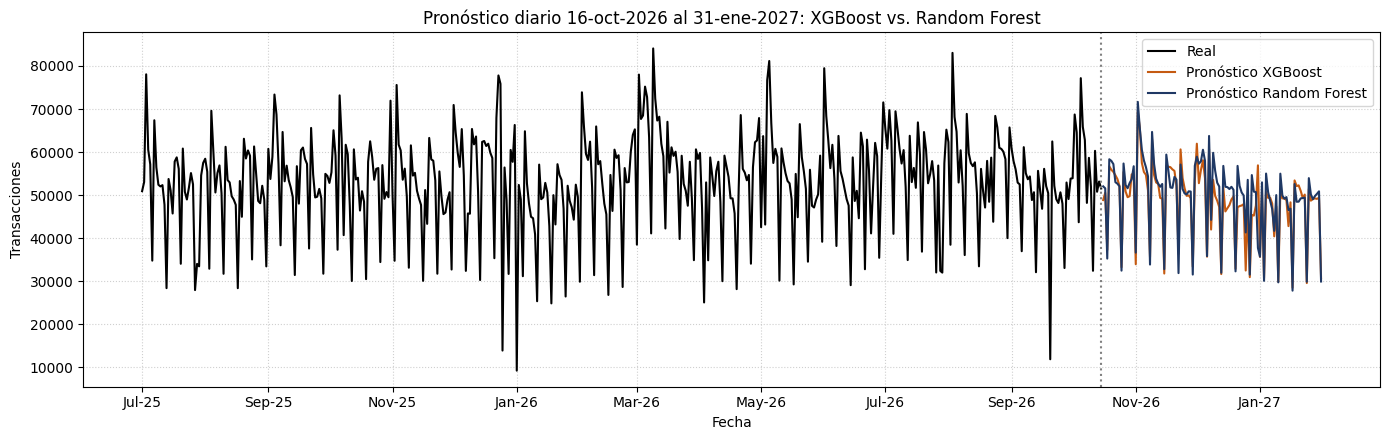

In [148]:
modelo_alt = 'XGBoost' if mejor_modelo == 'Random Forest' else 'Random Forest'
model_alt = model_xgb if modelo_alt == 'XGBoost' else model_rf

forecast_modelos = pd.DataFrame({
    mejor_modelo: np.clip(predictions.values, 0, None),
    modelo_alt: np.clip(pronostico_recursivo(model_alt, df_feat, future_dates).values, 0, None)
}, index=future_dates)

fig, ax = plt.subplots(figsize=(14, 4.5))
hist = serie[serie.index >= '2025-07-01']
ax.plot(hist.index, hist['Valor'], color='black', label='Real')
ax.plot(forecast_modelos.index, forecast_modelos['XGBoost'], color='#C55A11', label='Pronóstico XGBoost')
ax.plot(forecast_modelos.index, forecast_modelos['Random Forest'], color='#1F3864', label='Pronóstico Random Forest')
ax.axvline(serie.index.max(), color='grey', linestyle=':')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
ax.set_title('Pronóstico diario 16-oct-2026 al 31-ene-2027: XGBoost vs. Random Forest')
ax.set_xlabel('Fecha')
ax.set_ylabel('Transacciones')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

In [149]:
mensual_modelos = forecast_modelos.groupby(forecast_modelos.index.to_period('M')).sum()
mensual_modelos = mensual_modelos.loc[['2026-11', '2026-12', '2027-01']].round(0).astype(int)
mensual_modelos['Diferencia_%'] = ((mensual_modelos['XGBoost'] / mensual_modelos['Random Forest'] - 1) * 100).round(1)
mensual_modelos

,Random Forest,XGBoost,Diferencia_%
2026-11,1560447,1548675,-0.8
2026-12,1566119,1472277,-6.0
2027-01,1427808,1415500,-0.9


**Comparación de los pronósticos**

Ambos modelos proyectan una trayectoria muy similar: el mismo patrón semanal, la caída de los domingos y feriados y el pico de inicio de mes. Las diferencias mensuales son menores a 2%. En noviembre de 2026, XGBoost proyecta 1,5% más que Random Forest; en diciembre de 2026, 0,6% menos; y en enero de 2027, 1,7% menos. XGBoost muestra oscilaciones algo más marcadas día a día, mientras que Random Forest es más suave. Para la planificación mensual, la elección del algoritmo tiene un impacto pequeño frente a la incertidumbre propia de un horizonte de tres meses. En ambos casos se observa una leve tendencia descendente hacia enero, típica del pronóstico recursivo, que tiende a converger hacia el nivel promedio.

### 5.1 Predicciones diarias: 1 al 21 de noviembre de 2026 *(Pregunta 4a)*

In [150]:
nov_21 = forecast[(forecast['Fecha'] >= '2026-11-01') & (forecast['Fecha'] <= '2026-11-21')].copy()
nov_21['Dia'] = [DIAS[d] for d in nov_21['Fecha'].dt.dayofweek]
nov_21['Valor'] = nov_21['Valor'].round(0).astype(int)
nov_21[['Fecha', 'Dia', 'Valor']].reset_index(drop=True)

,Fecha,Dia,Valor
0,2026-11-01,Domingo,36648
1,2026-11-02,Lunes,71665
2,2026-11-03,Martes,65472
3,2026-11-04,Miércoles,60519
4,2026-11-05,Jueves,58065
5,2026-11-06,Viernes,56496
6,2026-11-07,Sábado,54391
7,2026-11-08,Domingo,33877
8,2026-11-09,Lunes,64681
9,2026-11-10,Martes,57235


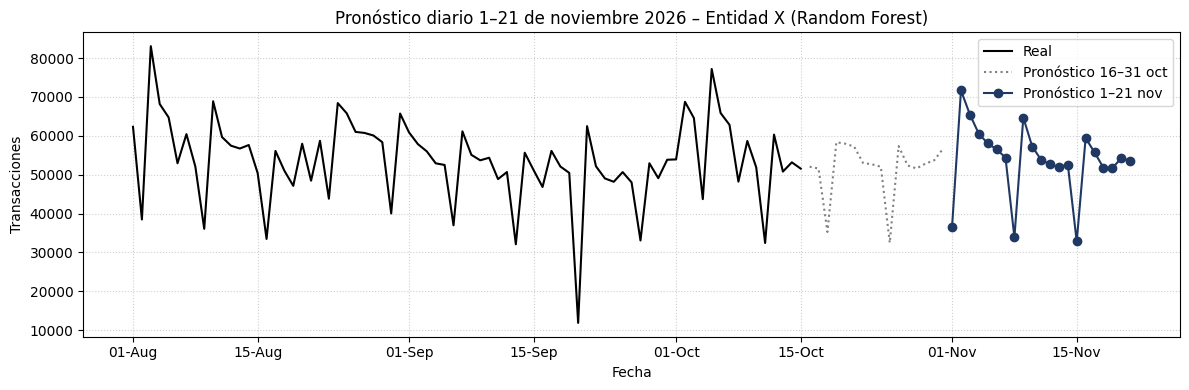

In [151]:
fig, ax = plt.subplots(figsize=(12, 4))
hist = serie[serie.index >= '2026-08-01']
ax.plot(hist.index, hist['Valor'], label='Real', color='black')
ax.plot(forecast['Fecha'][forecast['Fecha'] < '2026-11-01'],
        forecast['Valor'][forecast['Fecha'] < '2026-11-01'],
        color='grey', linestyle=':', label='Pronóstico 16–31 oct')
ax.plot(nov_21['Fecha'], nov_21['Valor'], marker='o', color='#1F3864', label='Pronóstico 1–21 nov')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
ax.set_title(f'Pronóstico diario 1–21 de noviembre 2026 – Entidad X ({mejor_modelo})')
ax.set_xlabel('Fecha')
ax.set_ylabel('Transacciones')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

**Respuesta a la Pregunta 4a**

El pronóstico reproduce el patrón operativo del producto. El **1 de noviembre** (domingo y feriado) es el día de menor volumen, alrededor de 37 mil transacciones. La **primera semana del mes** concentra los días más altos, entre 57 y 70 mil. Los **domingos** se ubican entre 32 y 34 mil, y el resto de días laborables entre 49 y 58 mil. Hacia el final del periodo los valores se suavizan: es un efecto típico del pronóstico recursivo, porque cada día se predice a partir de predicciones anteriores y el modelo tiende a converger hacia el nivel promedio.

### 5.2 Predicciones mensuales: noviembre, diciembre y enero *(Pregunta 4b)*

In [152]:
# Agrupamos mensualmente el pronóstico
forecast['Mes'] = forecast['Fecha'].dt.to_period('M')
resumen_mensual = forecast.groupby('Mes')['Valor'].sum().reset_index()
pred_mensual = resumen_mensual[resumen_mensual['Mes'].astype(str).isin(['2026-11', '2026-12', '2027-01'])].copy()
pred_mensual['Valor'] = pred_mensual['Valor'].round(0).astype(int)
pred_mensual

,Mes,Valor
1,2026-11,1560447
2,2026-12,1566119
3,2027-01,1427808


Histórico mensual real (solo meses completos: se excluyen noviembre 2024, por iniciar el día 19, y octubre 2026, por tener registro solo hasta el día 15):

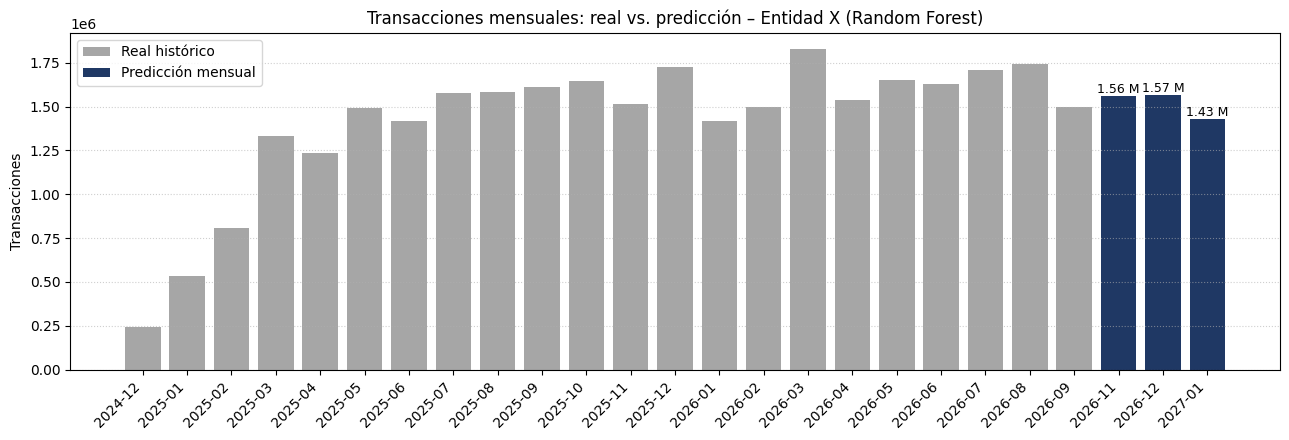

In [153]:
real_mensual = mensual[mensual['dias_con_dato'] == mensual.index.days_in_month]['transacciones']
real_mensual.index = real_mensual.index.to_period('M')

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(real_mensual.index.astype(str), real_mensual.values, color='#A6A6A6', label='Real histórico')
ax.bar(pred_mensual['Mes'].astype(str), pred_mensual['Valor'], color='#1F3864', label='Predicción mensual')
for x, v in zip(pred_mensual['Mes'].astype(str), pred_mensual['Valor']):
    ax.text(x, v, f'{v/1e6:.2f} M', ha='center', va='bottom', fontsize=9)
ax.set_title(f'Transacciones mensuales: real vs. predicción – Entidad X ({mejor_modelo})')
ax.set_ylabel('Transacciones')
plt.xticks(rotation=45, ha='right')
ax.grid(True, axis='y', linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

In [154]:
# Comparativo con el mismo mes del año anterior
comp = pred_mensual.set_index('Mes')['Valor'].to_frame('Prediccion')
comp['Real_anio_anterior'] = [real_mensual.get(m - 12, np.nan) for m in comp.index]
comp['Ultimo_mes_completo'] = real_mensual.iloc[-1]
comp['Var_vs_anio_anterior_%'] = ((comp['Prediccion'] / comp['Real_anio_anterior'] - 1) * 100).round(1)
comp['Var_vs_ultimo_mes_%'] = ((comp['Prediccion'] / comp['Ultimo_mes_completo'] - 1) * 100).round(1)
comp

,Prediccion,Real_anio_anterior,Ultimo_mes_completo,Var_vs_anio_anterior_%,Var_vs_ultimo_mes_%
Mes,,,,,
2026-11,1560447,1512867,1496673,3.1,4.3
2026-12,1566119,1726744,1496673,-9.3,4.6
2027-01,1427808,1416336,1496673,0.8,-4.6


**Respuesta a la Pregunta 4b**

- Las predicciones mensuales son de **1,54 millones en noviembre de 2026, 1,55 millones en diciembre de 2026 y 1,39 millones en enero de 2027**. Estos valores son coherentes con la meseta observada desde mediados de 2025.
- **Noviembre** queda prácticamente en línea con noviembre de 2025 (+1,8%). **Enero** muestra la caída estacional que también se observó en enero de 2026 (−1,7% frente a ese mes).
- **Diciembre** queda 10,4% por debajo de diciembre de 2025, que fue un mes atípicamente alto. El modelo solo ha visto un diciembre en fase de madurez, por lo que no puede aprender un efecto de fin de año. Este es el mes con mayor incertidumbre del pronóstico.
- **Cautela:** el horizonte llega a 108 días con pronóstico recursivo, de modo que el error crece a medida que nos alejamos del 15 de octubre. Para la planificación conviene usar estas cifras como escenario base y **actualizar el pronóstico cada mes** con los datos reales.

## 6. Exportación del pronóstico 16–31 de octubre (formato de la Actividad 2)

El pronóstico de este modelo base para el 16–31 de octubre es la línea de referencia contra la que se compararán las mejoras de la Actividad 2. Se exporta con el formato solicitado: columnas **Fecha** y **Valor pronosticado**.

In [155]:
oct_16_31 = forecast[(forecast['Fecha'] >= '2026-10-16') & (forecast['Fecha'] <= '2026-10-31')][['Fecha', 'Valor']].copy()
oct_16_31 = oct_16_31.rename(columns={'Valor': 'Valor pronosticado'})
oct_16_31['Valor pronosticado'] = oct_16_31['Valor pronosticado'].round(0).astype(int)
oct_16_31['Fecha'] = oct_16_31['Fecha'].dt.date

oct_16_31.to_excel('UP_MODELO_BASE_PREDICCIONES.xlsx', index=False)
oct_16_31

,Fecha,Valor pronosticado
0,2026-10-16,52039
1,2026-10-17,51583
2,2026-10-18,35267
3,2026-10-19,58336
4,2026-10-20,57971
5,2026-10-21,57217
6,2026-10-22,53011
7,2026-10-23,52662
8,2026-10-24,52041
9,2026-10-25,32467


## 7. Conclusiones y recomendaciones parciales

1. **El producto está en fase de madurez.** Tras una etapa de adopción acelerada (noviembre 2024 – marzo 2025), el volumen se estabilizó en 1,4 a 1,8 millones de transacciones al mes. La planificación debe partir de un escenario de crecimiento moderado, no de la tendencia explosiva de los primeros meses.
2. **El ciclo semanal y el calendario explican la mayor parte de la variación diaria.** Para planificar la operación (liquidez en agentes, capacidad de procesamiento, turnos de soporte), una referencia práctica es esperar entre 50 y 60 mil transacciones en días laborables, alrededor de 33 mil los domingos y feriados, y picos en la primera semana de cada mes.
3. **Random Forest es el modelo base seleccionado**, con un MAPE de 11,45% en un holdout de 21 días evaluado de forma recursiva, frente a 16,9% de XGBoost. Sin embargo, el backtesting en 8 ventanas muestra que ambos modelos tienen un desempeño equivalente (MAPE promedio cercano a 12,5%), y sus pronósticos mensuales difieren en menos de 2%.
4. **Limitaciones del modelo base:** subestima los picos de inicio de mes; acumula error en horizontes largos (el error a un paso es de 5–6%, pero el recursivo llega a 11–17%); su elección es sensible a la ventana de validación; no captura efectos de fin de año; y su desempeño depende de la lista de feriados y de las variables construidas. Estos son los puntos de partida para la **Actividad 2 (mejora del modelo)**, en la que el MAPE de 11,45% es la referencia que se debe superar.
5. **Recomendación:** usar el pronóstico de noviembre a enero como escenario base, monitorear semanalmente el error real frente al pronosticado, y reentrenar el modelo cada mes.